# Week 7 Take Home

This week has two parts. Complete **both**.

| Part | Lessons | Project |
|------|---------|---------|
| **A. Cleaning & Visualising Data** | `1-Cleaning & Visualising Data/` | Holiday weather |
| **B. Transforming & Combining Data** | `2-Transforming & Combining Data/` | GDP and life expectancy + your own World Bank project |

Data for both parts comes from the cohort database (schemas `week07` and `week08`). See `Data Access (SQL).md`.

---
# Part A: Cleaning & Visualising Data

### Solve `1-Cleaning & Visualising Data/1.ipynb` Tasks Below

### Solve `1-Cleaning & Visualising Data/2.ipynb` Tasks Below

## Project A: Holiday weather


There is nothing I like better than taking a holiday. In this project I am going to use the historic weather data from the Weather Underground for London to try to predict two good weather weeks to take off as holiday. Of course the weather in the summer of 2025 may be very different to 2020 but it should give some indication of when would be a good time to take a summer break.

## Getting the data

Weather Underground keeps historical weather data collected in many airports around the world. Right-click on the following URL and choose 'Open Link in New Window' (or similar, depending on your browser):

http://www.wunderground.com/history

When the new page opens start typing 'LHR' in the 'Location' input box and when the pop up menu comes up with the option 'LHR, United Kingdom' select it and then click on 'Submit'. 

When the next page opens with London Heathrow data, click on the 'Custom' tab and select the time period From: 1 January 2023 to: 31 December 2023 and then click on 'Get History'. The data for that year should then be displayed further down the page. 

You can copy each month's data directly from the browser to a text editor like Notepad or TextEdit, to obtain a single file with as many months as you wish.


Now load the CSV file into a dataframe making sure that any extra spaces are skipped:

### Step-1 Cleaning the data


### Step-2 Finding a summer break

According to meteorologists, summer extends for the whole months of June, July, and August in the northern hemisphere and the whole months of December, January, and February in the southern hemisphere. So create a dataframe that holds just those months using the `datetime` index.

---
# Part B: Transforming & Combining Data

### Provide `2-Transforming & Combining Data/1.ipynb` Tasks Solutions below (Execute them)

### Provide `2-Transforming & Combining Data/2.ipynb` Tasks Solutions below (Execute them)

### Provide `2-Transforming & Combining Data/2.ipynb` Assignment Solutions below (Execute them)

### Read and follow the below example analysis

## Project B: GDP and life expectancy

Richer countries can afford to invest more on healthcare, on work and road safety, and other measures that reduce mortality. On the other hand, richer countries may have less healthy lifestyles. Is there any relation between the wealth of a country and the life expectancy of its inhabitants?

The following analysis checks whether there is any correlation between the total gross domestic product (GDP) of a country in 2013 and the life expectancy of people born in that country in 2013.

## Getting the data

Two datasets of the World Bank are considered. One dataset, available at <http://data.worldbank.org/indicator/NY.GDP.MKTP.CD>, lists the GDP of the world's countries in current US dollars, for various years. The use of a common currency allows us to compare GDP values across countries. The other dataset, available at <http://data.worldbank.org/indicator/SP.DYN.LE00.IN>, lists the life expectancy of the world's countries. The datasets were downloaded as CSV files in March 2016.

In [1]:
import warnings
warnings.simplefilter('ignore', FutureWarning)

import pandas as pd

# Load Data from cohort database (schema week08). See "Data Access (SQL).md".
import sys, pathlib
_p = pathlib.Path.cwd()
while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p))
from db.dataraflow_db import run_query

YEAR = 2013
GDP_INDICATOR = 'NY.GDP.MKTP.CD'
gdpReset = run_query("SELECT * FROM week08.wb_gdp_2013")

LIFE_INDICATOR = 'SP.DYN.LE00.IN'
lifeReset = run_query("SELECT * FROM week08.wb_le_2013")
lifeReset.head()


,country,year,SP.DYN.LE00.IN
0,Arab World,2013,70.631305
1,Caribbean small states,2013,71.901964
2,Central Europe and the Baltics,2013,76.127583
3,East Asia & Pacific (all income levels),2013,74.604619
4,East Asia & Pacific (developing only),2013,73.657617


## Cleaning the data

Inspecting the data with `head()` and `tail()` shows that:

1. the first 34 rows are aggregated data, for the Arab World, the Caribbean small states, and other country groups used by the World Bank;
- GDP and life expectancy values are missing for some countries.

The data is therefore cleaned by:
1. removing the first 34 rows;
- removing rows with unavailable values.

In [2]:
gdpCountries = gdpReset[34:].dropna()
lifeCountries = lifeReset[34:].dropna()

## Transforming the data

The World Bank reports GDP in US dollars and cents. To make the data easier to read, the GDP is converted to millions of British pounds (the author's local currency) with the following auxiliary functions, using the average 2013 dollar-to-pound conversion rate provided by <http://www.ukforex.co.uk/forex-tools/historical-rate-tools/yearly-average-rates>. 

In [3]:
def roundToMillions (value):
    return round(value / 1000000)

def usdToGBP (usd):
    return usd / 1.564768

GDP = 'GDP (£m)'
gdpCountries[GDP] = gdpCountries[GDP_INDICATOR].apply(usdToGBP).apply(roundToMillions)
gdpCountries.head()

,country,year,NY.GDP.MKTP.CD,GDP (£m)
34,Afghanistan,2013,2.045894e+10,13075
35,Albania,2013,1.278103e+10,8168
36,Algeria,2013,2.097035e+11,134016
38,Andorra,2013,3.249101e+09,2076
39,Angola,2013,1.383568e+11,88420


The unnecessary columns can be dropped.

In [4]:
COUNTRY = 'country'
headings = [COUNTRY, GDP]
gdpClean = gdpCountries[headings]
gdpClean.head()

,country,GDP (£m)
34,Afghanistan,13075
35,Albania,8168
36,Algeria,134016
38,Andorra,2076
39,Angola,88420


The World Bank reports the life expectancy with several decimal places. After rounding, the original column is discarded.

In [5]:
LIFE = 'Life expectancy (years)'
lifeCountries[LIFE] = lifeCountries[LIFE_INDICATOR].apply(round)
headings = [COUNTRY, LIFE]
lifeClean = lifeCountries[headings]
lifeClean.head()

,country,Life expectancy (years)
34,Afghanistan,60
35,Albania,78
36,Algeria,75
39,Angola,52
40,Antigua and Barbuda,76


## Combining the data

The tables are combined through an inner join on the common 'country' column. 

In [6]:
gdpVsLife = pd.merge(gdpClean, lifeClean, on=COUNTRY, how='inner')
gdpVsLife.head()

,country,GDP (£m),Life expectancy (years)
0,Afghanistan,13075,60
1,Albania,8168,78
2,Algeria,134016,75
3,Angola,88420,52
4,Antigua and Barbuda,767,76


## Calculating the correlation

To measure if the life expectancy and the GDP grow together, the Spearman rank correlation coefficient is used. It is a number from -1 (perfect inverse rank correlation: if one indicator increases, the other decreases) to 1 (perfect direct rank correlation: if one indicator increases, so does the other), with 0 meaning there is no rank correlation. A perfect correlation doesn't imply any cause-effect relation between the two indicators. A p-value below 0.05 means the correlation is statistically significant.

In [7]:
from scipy.stats import spearmanr

gdpColumn = gdpVsLife[GDP]
lifeColumn = gdpVsLife[LIFE]
(correlation, pValue) = spearmanr(gdpColumn, lifeColumn)
print('The correlation is', correlation)
if pValue < 0.05:
    print('It is statistically significant.')
else:
    print('It is not statistically significant.')

The correlation is 0.5010232389671027
It is statistically significant.


The value shows a direct correlation, i.e. richer countries tend to have longer life expectancy, but it is not very strong.

## Showing the data

Measures of correlation can be misleading, so it is best to see the overall picture with a scatterplot. The GDP axis uses a logarithmic scale to better display the vast range of GDP values, from a few million to several billion (million of million) pounds.

<Axes: xlabel='GDP (£m)', ylabel='Life expectancy (years)'>

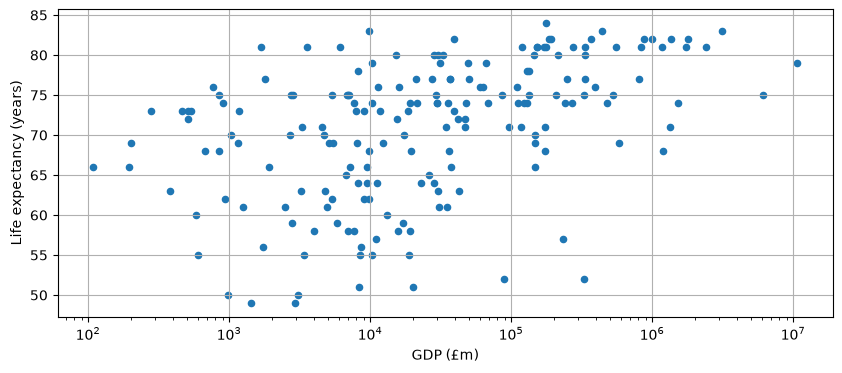

In [8]:
%matplotlib inline
gdpVsLife.plot(x=GDP, y=LIFE, kind='scatter', grid=True, logx=True, figsize=(10, 4))

The plot shows there is no clear correlation: there are rich countries with low life expectancy, poor countries with high expectancy, and countries with around 10 thousand (10<sup>4</sup>) million pounds GDP have almost the full range of values, from below 50 to over 80 years. Towards the lower and higher end of GDP, the variation diminishes. Above 40 thousand million pounds of GDP (3rd tick mark to the right of 10<sup>4</sup>), most countries have an expectancy of 70 years or more, whilst below that threshold most countries' life expectancy is below 70 years. 

Comparing the 10 poorest countries and the 10 countries with the lowest life expectancy shows that total GDP is a rather crude measure. The population size should be taken into account for a more precise definiton of what 'poor' and 'rich' means. Furthermore, looking at the countries below, droughts and internal conflicts may also play a role in life expectancy. 

In [9]:
# the 10 countries with lowest GDP
gdpVsLife.sort_values(GDP).head(10)

,country,GDP (£m),Life expectancy (years)
87,Kiribati,108,66
141,Sao Tome and Principe,195,66
111,"Micronesia, Fed. Sts.",202,69
168,Tonga,277,73
37,Comoros,383,63
157,St. Vincent and the Grenadines,461,73
140,Samoa,509,73
180,Vanuatu,512,72
65,Grenada,538,73
60,"Gambia, The",578,60


In [10]:
# the 10 countries with lowest life expectancy
gdpVsLife.sort_values(LIFE).head(10)

,country,GDP (£m),Life expectancy (years)
95,Lesotho,1418,49
160,Swaziland,2916,49
146,Sierra Leone,3092,50
32,Central African Republic,983,50
41,Cote d'Ivoire,19998,51
33,Chad,8276,51
124,Nigeria,329100,52
3,Angola,88420,52
68,Guinea-Bissau,605,55
153,South Sudan,8473,55


## Conclusions

To sum up, there is no strong correlation between a country's wealth and the life expectancy of its inhabitants: there is often a wide variation of life expectancy for countries with similar GDP, countries with the lowest life expectancy are not the poorest countries, and countries with the highest expectancy are not the richest countries. Nevertheless there is some relationship, because the vast majority of countries with a life expectancy below 70 years is on the left half of the scatterplot.

Using the [NY.GDP.PCAP.PP.CD](http://data.worldbank.org/indicator/NY.GDP.PCAP.PP.CD) indicator, GDP per capita in current 'international dollars', would make for a better like-for-like comparison between countries, because it would take population and purchasing power into account. Using more specific data, like expediture on health, could also lead to a better analysis.

### Assessment - NOW IS YOUR TURN

**Create your own project**
Create a completely new project and choose another two of the
hundreds of World Bank indicators and see if there is any correlation between them. If
there is a choice of similar indicators, choose one that leads to meaningful
comparisons between countries.

Look at the results you obtained and take a few moments to assess how they differ.


## GOOD LUCK!

<!-- practice:start -->
---
## 🔁 SQL Practice

This week you cleaned messy weather data and combined World Bank tables in pandas. Now do the same jobs **in SQL**, straight from the raw tables: real analysts clean and combine data in the database before it ever reaches pandas.

**How it works**
1. Run the **practice setup** cell first (and again after restarting the kernel). It connects with your **read-only** account.
2. **SQL tasks:** write your query between the triple quotes and run the cell. `p.sql(...)` shows your result and
   says ✅ or ❌, and whether the **shape** (rows × columns) is right. Match the column order, sort order and rounding
   asked for (column *names* aren't checked).
3. Run `p.score()` at the end to see your practice score.

Refresh your memory with `Week-6 (Numpy & Pandas-1)/4-Intermediate SQL/Intermediate SQL.ipynb`.

In [14]:
# --- practice setup: run this cell first (don't edit it) ---
import sys, pathlib
_p = pathlib.Path.cwd()
while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p))
from db.practice import Practice, q

EXPECTED = {
 "s01": [
  [
   1,
   1
  ],
  "1ba5edf59854386be920ac9fd3e4a2af3bb6369bf2a1aef78dcdf908c96d70a9"
 ],
 "s02": [
  [
   5,
   3
  ],
  "19042d389224a7f56403ad9636ed581989f6639acadf45b15461f55cd6258da7"
 ],
 "s03": [
  [
   10,
   3
  ],
  "e3e296058facb3595b46ac98fb75d445a82240fc775f3188d029eabc5a362ddb"
 ],
 "s04": [
  [
   1,
   1
  ],
  "ba4a24ee999caa9e01607eb78856b7212bcce521b0f6fd42d8aa90541c10382d"
 ],
 "s05": [
  [
   1,
   2
  ],
  "8153d8bbbc1b43b88ce7e4ea0c99a4ac07f4b19e0f62a9a1e04df3271f2ad3df"
 ]
}   # fingerprints only: the answers are not stored here
TITLES = {
 "s01": "Cleaning a messy column",
 "s02": "Dates: a date range",
 "s03": "Combining tables (JOIN)",
 "s04": "What gets lost in a join?",
 "s05": "Window: the driest summer week"
}
p = Practice(EXPECTED, TITLES)
print(f"Practice ready: {len(TITLES)} tasks. Connected as:", q("SELECT CURRENT_USER AS u").u[0])

Practice ready: 5 tasks. Connected as: intern_readonly


### SQL Task 1 · Cleaning a messy column

`week07.london_2014` is the **raw** export: the last column is literally named `WindDirDegrees<br />` and every
value ends in `<br />` (e.g. `'186<br />'`). Clean it **in SQL**: remove the `<br />`, convert to an integer, and
count the days when the wind direction was **greater than 350 degrees**.

**Return:** one row, one column (`days_over_350`).
💡 `REPLACE(...)`, `TRY_CAST(... AS int)`, and bracket-quote the odd column name: `[WindDirDegrees<br />]`.

In [15]:
SQL_01 = """
    WITH windDir AS (SELECT  [WindDirDegrees<br />],
                            CAST(REPLACE([WindDirDegrees<br />], '<br />', '') AS INT) AS WindDirDegrees
                        FROM week07.london_2014)
        SELECT COUNT(WindDirDegrees) AS days_over_350
        FROM windDir
        WHERE WindDirDegrees > 350
"""
p.sql("s01", SQL_01)

,days_over_350
0,5


✅ s01: correct!


,days_over_350
0,5


### SQL Task 2 · Dates: a date range

`GMT` is stored as **text** like `'2014-1-1'`. Convert it to a real date and return London's weather for
**8–12 December 2014** (inclusive).

**Return:** `day` (a date), `Max TemperatureC`, `Min TemperatureC`, sorted by `day`.
💡 `TRY_CONVERT(date, GMT)` and `BETWEEN`.

In [19]:
SQL_02 = """
    SELECT TRY_CONVERT(Date, GMT) AS day,
            [Max TemperatureC],
            [Min TemperatureC]
    FROM week07.london_2014
    WHERE TRY_CONVERT(Date, GMT) BETWEEN '2014-12-08' AND '2014-12-12' 
    ORDER BY day
"""
p.sql("s02", SQL_02)

,day,Max TemperatureC,Min TemperatureC
0,2014-12-08,7,1
1,2014-12-09,12,-1
2,2014-12-10,9,6
3,2014-12-11,10,5
4,2014-12-12,9,2


✅ s02: correct!


,day,Max TemperatureC,Min TemperatureC
0,2014-12-08,7,1
1,2014-12-09,12,-1
2,2014-12-10,9,6
3,2014-12-11,10,5
4,2014-12-12,9,2


### SQL Task 3 · Combining tables (JOIN)

Join `week08.wb_gdp_2013` and `week08.wb_le_2013` on `country`. Among entries with GDP **below 10 billion USD**
and a known life expectancy, return the **10 with the highest life expectancy**.

**Return:** `country`, `gdp_bn_usd` (GDP in billions, **rounded to 2 dp**), `life_expectancy` (**rounded to 1 dp**),
sorted by life expectancy (highest first), then `country` (A→Z) for ties.

In [23]:
SQL_03 = """
    SELECT TOP 10
            a.country,
            ROUND([NY.GDP.MKTP.CD]/1000000000, 2) AS gdp_bn_usd,
            ROUND([SP.DYN.LE00.IN], 1) AS life_expectancy
    FROM week08.wb_gdp_2013 a
    JOIN week08.wb_le_2013 b
        ON a.country = b.country
    WHERE [NY.GDP.MKTP.CD] < 10000000000 AND
        [SP.DYN.LE00.IN] IS NOT NULL
    ORDER BY life_expectancy DESC, country ASC
"""
p.sql("s03", SQL_03)

,country,gdp_bn_usd,life_expectancy
0,Faeroe Islands,2.61,81.3
1,Malta,9.64,80.7
2,Bermuda,5.57,80.6
3,Maldives,2.79,76.6
4,Antigua and Barbuda,1.20,75.8
5,Barbados,4.28,75.3
6,"Bahamas, The",8.43,75.1
7,St. Lucia,1.33,74.9
8,Montenegro,4.46,74.8
9,Seychelles,1.41,74.2


✅ s03: correct!


,country,gdp_bn_usd,life_expectancy
0,Faeroe Islands,2.61,81.3
1,Malta,9.64,80.7
2,Bermuda,5.57,80.6
3,Maldives,2.79,76.6
4,Antigua and Barbuda,1.20,75.8
5,Barbados,4.28,75.3
6,"Bahamas, The",8.43,75.1
7,St. Lucia,1.33,74.9
8,Montenegro,4.46,74.8
9,Seychelles,1.41,74.2


### SQL Task 4 · What gets lost in a join?

In the lesson, `dropna()` removed rows before the merge. Count what would be lost: how many rows of
`week08.wb_gdp_2013` have **no usable match**, meaning either GDP is NULL, or the life-expectancy value for that
country is NULL (or missing)?

**Return:** one row, one column (`rows_lost`).
💡 `LEFT JOIN` and test for NULLs on both sides.

In [24]:
SQL_04 = """
    SELECT COUNT(*)
    FROM week08.wb_gdp_2013 a
    LEFT JOIN week08.wb_le_2013 b
        ON a.country = b.country
    WHERE [NY.GDP.MKTP.CD] IS NULL OR
    [SP.DYN.LE00.IN] IS NULL
"""
p.sql("s04", SQL_04)

,
0,29


✅ s04: correct!


,
0,29


### SQL Task 5 · Window: the driest summer week

For the **Holiday weather** project: using London's **summer** (June, July, August 2014), find the **7-day
period with the least total rain**. A period is identified by its **start date** (that day + the next 6 days,
all inside the summer). If several periods tie, take the earliest.

**Return:** one row: `start_day` (a date), `rain_mm_7d` (**rounded to 2 dp**).
💡 `SUM(Precipitationmm) OVER (ORDER BY day ROWS BETWEEN CURRENT ROW AND 6 FOLLOWING)` in a CTE, and only keep
start days whose window has a full 7 days.

In [ ]:
SQL_05 = """
    
"""
p.sql("s05", SQL_05)

,start_day,rain_mm_7d
0,2014-06-19,0.0


✅ s05: correct!


,start_day,rain_mm_7d
0,2014-06-19,0.0


### Practice score
Run this when you're done.

In [28]:
p.score()

Task Type                          Topic Result
 s01  SQL        Cleaning a messy column      ✅
 s02  SQL            Dates: a date range      ✅
 s03  SQL        Combining tables (JOIN)      ✅
 s04  SQL      What gets lost in a join?      ✅
 s05  SQL Window: the driest summer week      ✅
SQL score: 5 / 5


,Task,Type,Topic,Result
0,s01,SQL,Cleaning a messy column,✅
1,s02,SQL,Dates: a date range,✅
2,s03,SQL,Combining tables (JOIN),✅
3,s04,SQL,What gets lost in a join?,✅
4,s05,SQL,Window: the driest summer week,✅


<!-- practice:end -->

---
## 📰 Article Link

Write a **detailed article** about this week's work. It should cover:

- **What you learnt:** the key concepts, tools and techniques from this week.
- **What you solved:** the tasks and projects you worked on, and how you approached them.
- **Challenges you faced:** what was hard, confusing or didn't work at first.
- **How you overcame them:** what you tried, what finally worked, and what you'd do differently.
- **Anything else you want to share:** insights, results, visuals, or advice for others learning this.

Publish it, then paste the article's **URL** in the empty cell below (double-click the cell to edit it).